# 📉 TRABAJO PRÁCTICO FINAL 📈
INTRODUCCIÓN A LA INGENIERÍA DE DATOS
### Entregable Técnico: Pipeline ETL, Modelado Relacional (2NF), Data Warehouse y Visualización Interactiva

* 🎓 **Instancia:** Trabajo Práctico Final — Entregable Técnico
* 👩‍🏫 **Docente:** Nicolás Guillermo Tripp
* 👩‍🎓 **Alumna:** González Ma. Cecilia
* 🗂️ **Dominio de Investigación:** Salud Mental Materna, Temperamento y Sueño Infantil en el Posparto

> 🤖 **Declaración de Uso de Inteligencia Artificial:**  
> Además de los usos declarados de IA para la generación de scripts de Python (detallados en cada celda), esta herramienta se utilizó para simplificar sintaxis de código, mejorar la redacción de celdas de texto, discutir ideas y explicar, ejemplificar conceptos teóricos.  
> **Modelo utilizado en todo el proceso:** *Gemini 4 m.Hydrogen Thinking*.


## 📦 0. CONFIGURACIÓN DEL ENTORNO: Importación de Librerías

Antes de iniciar el flujo de ingeniería de datos, se centraliza la importación de todas las librerías y dependencias necesarias en un único bloque inicial. Esto garantiza un **entorno de ejecución limpio, ordenado y 100% reproducible** de principio a fin en Google Colab.

### 🛠️ Stack Tecnológico Utilizado

* 🌐 **Ingesta de Datos (`kagglehub`)**
* 🐼 **Manipulación y Cálculo Numérico (`pandas`, `numpy`)**
* 🗄️ **Persistencia y Modelado SQL (`sqlite3`)**
* 📊 **Visualización Exploratoria (`matplotlib`, `seaborn`)**
* 🚀 **Interfaz Interactiva (`streamlit`, `plotly`)** *(instaladas y ejecutadas en la Sección 10 para el despliegue del tablero)*

In [1]:
# IMPORTS
import kagglehub
from kagglehub import KaggleDatasetAdapter
import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns

## 📥 1. PROCESO ETL — EXTRACT (Ingesta Reproducible desde Repositorio Público)

🌐 **Acceso abierto y trazabilidad:**  
Para garantizar la reproducibilidad total del cuaderno sin depender de rutas locales o archivos privados, se utilizó la API oficial de Kaggle (`kagglehub`) para descargar directamente el dataset crudo (`Dataset_maternal_mental_health_infant_sleep.csv`).

🤱👶 **Contexto clínico del dataset:**  
Los datos provienen de un **estudio clínico perinatal francófono** ($n = 410$ díadas madre-bebé) que analiza cómo la sintomatología emocional materna (ansiedad, depresión posparto y trauma asociado al parto) y el temperamento del lactante inciden en la duración y continuidad del sueño infantil durante los primeros tres meses de vida.

> 💬 **Uso de IA:**  
> *"Arma un script en Python para descargar directamente el dataset `'thedevastator/impact-of-maternal-mental-health-on-infant-sleep'` (archivo `'Dataset_maternal_mental_health_infant_sleep.csv'`) en un DataFrame de pandas llamado `df`, sin tener que subir archivos manualmente a Colab."*



In [2]:
df = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    "thedevastator/impact-of-maternal-mental-health-on-infant-sleep",
    "Dataset_maternal_mental_health_infant_sleep.csv",
    pandas_kwargs={"encoding": "latin-1"}
)

if not df.empty:
    print(f"\nEl dataset se cargó adecuadamente.")

/tmp/ipykernel_47244/4136713823.py:1: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


Using Colab cache for faster access to the 'impact-of-maternal-mental-health-on-infant-sleep' dataset.


/usr/local/lib/python3.13/dist-packages/kagglehub/pandas_datasets.py:92: DtypeWarning: Columns (6,61) have mixed types. Specify dtype option on import or set low_memory=False.
  result = read_function(



El dataset se cargó adecuadamente.


## 🔍 2. PROCESO ETL — TRANSFORM: Auditoría Exploratoria Inicial

Dado que se trata de datos no recolectados de forma propia, el primer paso de transformación consistió en ejecutar una **auditoría estructural global** para diagnosticar dimensiones, registros duplicados, tipos de datos y proporción de valores faltantes.

> 💬 **Uso de IA:**  
> *"Arma un script de python para realizar una inspeccion de los datos que contiene el .csv del dataset que cargamos. Como no son datos recolectados por mi, quiero inspecccionarlos y ver muestras de la información que contiene, nombres de columnas, cuenta la cantidad total de filas/columnas, cuenta cuantos datos faltantes hay."*

* 🛠️ **Implementación:** Se encapsuló este diagnóstico inicial en una función reutilizable `inspeccionar_dataset(df)` para monitorear la integridad de los datos antes y después de la intervención de limpieza.

In [3]:
def inspeccionar_dataset(df):
    print("=" * 60)
    print("1. DIMENSIONES GENERALES Y DUPLICADOS")
    print("=" * 60)
    print(f"Total de filas:    {df.shape[0]}")
    print(f"Total de columnas: {df.shape[1]}")
    print(f"Filas duplicadas:  {df.duplicated().sum()}\n")

    print("=" * 60)
    print("2. NOMBRES DE COLUMNAS, TIPOS DE DATOS Y VALORES FALTANTES")
    print("=" * 60)
    resumen = pd.DataFrame({
        "Tipo de dato": df.dtypes,
        "No nulos": df.notnull().sum(),
        "Nulos (cantidad)": df.isnull().sum(),
        "Nulos (%)": (df.isnull().mean() * 100).round(2)
    })
    print(resumen.to_string(), "\n")

    print("=" * 60)
    print("3. MUESTRAS DE DATOS (Primeras 5 filas)")
    print("=" * 60)
    print(df.head(5), "\n")

    print("=" * 60)
    print("4. ÚLTIMAS 5 FILAS")
    print("=" * 60)
    print(df.tail(5), "\n")

    print("=" * 60)
    print("5. RESUMEN ESTADÍSTICO (Variables numéricas y categóricas)")
    print("=" * 60)
    print(df.describe(include="all").T[["count", "unique", "top", "mean", "min", "max"]])

# Ejecución sobre el DataFrame cargado previamente
inspeccionar_dataset(df)

1. DIMENSIONES GENERALES Y DUPLICADOS
Total de filas:    1048292
Total de columnas: 64
Filas duplicadas:  1047881

2. NOMBRES DE COLUMNAS, TIPOS DE DATOS Y VALORES FALTANTES
                           Tipo de dato  No nulos  Nulos (cantidad)  Nulos (%)
Participant_number              float64       410           1047882      99.96
Type_parents                    float64       410           1047882      99.96
Birth_1mth_M_inclusion          float64       410           1047882      99.96
Birth_12mth_M_inclusion         float64       410           1047882      99.96
Age                             float64       410           1047882      99.96
Marital_status                  float64       410           1047882      99.96
Marital_status_Autre             object         2           1048290     100.00
Marital_status_edit             float64       410           1047882      99.96
Education                       float64       410           1047882      99.96
Gestationnal_age                floa

## 🧹 3. PROCESO ETL — TRANSFORM: Depuración de "Filas Fantasma"

🚨 **Anomalía estructural detectada:**  
La auditoría inicial evidenció un bloque extenso de filas completamente vacías al final del archivo `.csv`, verificándose registros clínicos reales únicamente hasta la **fila 410** (índice `409` en Python). Estas "filas fantasma" inflan artificialmente el tamaño de la tabla y sesgan el cálculo real de porcentajes de datos faltantes (`NaN`).

> 💬 **Uso de IA:**  
> *"Detecté el problema de que hay más de un millón de filas completamente vacías al final del archivo. Armame un script simple en Python que: 1) elimine todas las filas 100% vacías guardando el resultado en un nuevo df: `df_corregido`, 2) verifique que el último índice con datos sea el `409` e imprima cuántas filas fantasma se eliminaron y cuántas válidas quedaron, y 3) vuelva a ejecutar mi función `inspeccionar_dataset` sobre `df_corregido`."*

* ✅ **Decisión metodológica:** Tras validar que el último índice con información es el `409` y que todas las filas posteriores son 100% nulas, se recortó el DataFrame creando `df_corregido` con las **410 entradas de datos válidos**.

In [4]:
# 1. Eliminar filas 100% vacías y guardar en df_corregido
df_corregido = df.dropna(how="all").copy()

# 2. Verificar el último índice y cuántas filas se eliminaron
ultimo_indice = df_corregido.index.max()
print(f"Último índice con datos: {ultimo_indice}")
print(f"Filas fantasma eliminadas: {len(df) - len(df_corregido)}")
print(f"Filas válidas restantes: {len(df_corregido)}\n")

# 3. Inspeccionar la tabla ya limpia
pd.set_option("display.max_rows", 100)
inspeccionar_dataset(df_corregido)

Último índice con datos: 409
Filas fantasma eliminadas: 1047882
Filas válidas restantes: 410

1. DIMENSIONES GENERALES Y DUPLICADOS
Total de filas:    410
Total de columnas: 64
Filas duplicadas:  0

2. NOMBRES DE COLUMNAS, TIPOS DE DATOS Y VALORES FALTANTES
                           Tipo de dato  No nulos  Nulos (cantidad)  Nulos (%)
Participant_number              float64       410                 0       0.00
Type_parents                    float64       410                 0       0.00
Birth_1mth_M_inclusion          float64       410                 0       0.00
Birth_12mth_M_inclusion         float64       410                 0       0.00
Age                             float64       410                 0       0.00
Marital_status                  float64       410                 0       0.00
Marital_status_Autre             object         2               408      99.51
Marital_status_edit             float64       410                 0       0.00
Education                      

## 🔎 4. PROCESO ETL — TRANSFORM: Diagnóstico de Variables Tipo `object` y Barrido General

🧐 **Inconsistencia de tipado:**  
Si bien el cuestionario original codifica todas sus respuestas numéricamente (`float64`), la inspección reveló dos columnas interpretadas como texto (`object`):
1. `Marital_status_Autre`
2. `Sleep_night_duration_bb1`

> 💬 **Uso de IA:**  
> *"Tengo dos variables type object, considero que pueden ser errores. Una es marital status_autre y la otra es Sleep_night_duration_bb1. Veamos en detalle e inspeccionemos estas variables para ver si es algún error en la carga de los datos. Recuerda que yo no tome los datos."*

* 📋 **Alcance del control:** Se inspeccionaron los valores únicos de ambas variables y luego se extendió el barrido de tipos y valores de ejemplo a **todas las columnas restantes** para descartar códigos ocultos o formatos mixtos.

In [5]:
print("--- VALORES EN Marital_status_Autre ---")
print(df_corregido["Marital_status_Autre"].dropna().unique())

print("\n--- TODOS LOS VALORES ÚNICOS EN Sleep_night_duration_bb1 ---")
print(df_corregido["Sleep_night_duration_bb1"].dropna().unique())

print("\n--- COLUMNAS A INSPECCIONAR ---")

# Definimos las 4 columnas que queremos comparar
cols_relacionadas = [
    "Marital_status",
    "Marital_status_Autre",
    "Marital_status_edit",
    "Sleep_night_duration_bb1"
]

# Recorremos esas 4 columnas una por una para ver su tipo de dato y 2 ejemplos
for c in cols_relacionadas:
    print(f"{c} -> tipo: {df_corregido[c].dtype} | ejemplo: {df_corregido[c].dropna().head(2).tolist()}")

--- VALORES EN Marital_status_Autre ---
['Pacsée' 'Pacse']

--- TODOS LOS VALORES ÚNICOS EN Sleep_night_duration_bb1 ---
['10:00' '11:00' '12:00' '10:30' '08:00' '06:00' '09:00' '07:00' '09:30'
 '05:00' '11:30' '11:15' '99:99' '07:30' '08:30']

--- COLUMNAS A INSPECCIONAR ---
Marital_status -> tipo: float64 | ejemplo: [2.0, 2.0]
Marital_status_Autre -> tipo: object | ejemplo: ['Pacsée', 'Pacse']
Marital_status_edit -> tipo: float64 | ejemplo: [2.0, 2.0]
Sleep_night_duration_bb1 -> tipo: object | ejemplo: ['10:00', '11:00']


In [6]:
for col in df_corregido.columns:
    tipo = df_corregido[col].dtype
    valores_unicos = df_corregido[col].dropna().unique()
    ejemplos = valores_unicos[:3].tolist()
    print(f"{col} -> tipo: {tipo} | ejemplos: {ejemplos}")

Participant_number -> tipo: float64 | ejemplos: [1.0, 2.0, 3.0]
Type_parents -> tipo: float64 | ejemplos: [1.0]
Birth_1mth_M_inclusion -> tipo: float64 | ejemplos: [1.0]
Birth_12mth_M_inclusion -> tipo: float64 | ejemplos: [1.0]
Age -> tipo: float64 | ejemplos: [34.0, 33.0, 37.0]
Marital_status -> tipo: float64 | ejemplos: [2.0, 1.0, 3.0]
Marital_status_Autre -> tipo: object | ejemplos: ['Pacsée', 'Pacse']
Marital_status_edit -> tipo: float64 | ejemplos: [2.0, 1.0, 3.0]
Education -> tipo: float64 | ejemplos: [5.0, 4.0, 3.0]
Gestationnal_age -> tipo: float64 | ejemplos: [37.0, 42.0, 41.0]
Type_pregnancy -> tipo: float64 | ejemplos: [1.0, 2.0]
sex_baby1 -> tipo: float64 | ejemplos: [1.0, 2.0]
CBTS_M_3 -> tipo: float64 | ejemplos: [0.0, 1.0, 2.0]
CBTS_M_4 -> tipo: float64 | ejemplos: [0.0, 2.0, 1.0]
CBTS_M_5 -> tipo: float64 | ejemplos: [0.0, 1.0, 2.0]
CBTS_M_6 -> tipo: float64 | ejemplos: [0.0, 1.0, 2.0]
CBTS_M_7 -> tipo: float64 | ejemplos: [0.0, 1.0, 3.0]
CBTS_M_8 -> tipo: float64 | ej

## ⚙️ 5. PROCESO ETL — TRANSFORM: Tipificación Estricta y Depuración de Redundancias

A partir de la auditoría por columna, se ejecutaron tres **decisiones metodológicas de curaduría**:

* 🗑️ **Eliminación de variables constantes (varianza nula):** Se descartaron `Type_parents`, `Birth_1mth_M_inclusion`, `Birth_12mth_M_inclusion` y `Child_survey_participation`. Todas registran un valor constante igual a `1` (filtros administrativos y de inclusión al estudio), por lo que no aportan capacidad explicativa ni discriminante.
* 🔄 **Depuración de columnas redundantes de estado civil:** En `Marital_status_Autre` se observaron respuestas abiertas que los propios autores del estudio ya habían estandarizado en `Marital_status_edit`. Para evitar duplicidad semántica, se eliminaron `Marital_status` y `Marital_status_Autre`, conservando únicamente **`Marital_status_edit`**.
* 🔢 **Tipificación estricta a enteros (`int64`):** Se convirtieron `Participant_number` y `Age` de `float64` a `int64`, para optimizar el almacenamiento y garantizar claves primarias limpias.

> 💬 **Uso de IA:**  
> *"Arma un script en Python para trabajar sobre las variables de mi dataframe (df_corregido), que realice las siguientes tareas de tipificación, depuración y transformación de mis variables: 1. Convertir tanto 'Participant_number' como 'Age' al tipo entero int64. 2. Eliminar las variables constantes de inclusión ('Child_survey_participation', 'Type_parents', 'Birth_1mth_M_inclusion', 'Birth_12mth_M_inclusion') y las columnas redundantes de estado civil ('Marital_status', 'Marital_status_Autre'), conservando 'Marital_status_edit'."*

In [7]:
# Transformar ID y Edad a entero (int64)
cols_enteras = ["Participant_number", "Age"]
df_corregido[cols_enteras] = df_corregido[cols_enteras].astype("int64")

# Depurar variables constantes de inclusión y columnas redundantes de estado civil
cols_a_eliminar = [
    "Child_survey_participation",
    "Type_parents",
    "Birth_1mth_M_inclusion",
    "Birth_12mth_M_inclusion",
    "Marital_status",
    "Marital_status_Autre",
]

df_corregido = df_corregido.drop(columns=cols_a_eliminar, errors="ignore")

# Comprobación rápida
print("Tipos actualizados:\n")
print(df_corregido[cols_enteras].dtypes)
print(f"\nDimensiones actuales: {df_corregido.shape}")

Tipos actualizados:

Participant_number    int64
Age                   int64
dtype: object

Dimensiones actuales: (410, 58)


## ⏱️ 6. PROCESO ETL — TRANSFORM: Resolución del Código `'99:99'` y Conversión Horaria

🚨 **Anomalía detectada en `Sleep_night_duration_bb1`:**  
Esta variable registraba la duración del sueño nocturno infantil en formato texto `'HH:MM'` e incluía el código **`'99:99'`**. Desde el punto de vista fisiológico y clínico, este valor es imposible (un lactante no puede dormir 99 horas y 99 minutos) y corresponde a una codificación heredada de dato faltante.

> 💬 **Uso de IA:**  
> *"Arma un script simple en Python para corregir la variable 'Sleep_night_duration_bb1': reemplaza el código erróneo '99:99' por un valor nulo (np.nan), separa las horas y los minutos usando ':' como delimitador, conviértelos a float y calcula la duración total en horas decimales, comprobando al final el tipo de dato y la cantidad de nulos."*

* ✅ **Decisión metodológica:** Al tratarse de un **único registro** en toda la muestra ($n = 1/410$), se optó por **recodificarlo como valor nulo (`np.nan` $\rightarrow$ `NULL` en SQLite)** en lugar de eliminar la fila completa (lo que implicaría perder datos válidos de esa madre en los cuestionarios psicológicos) o imputar una mediana artificial. Posteriormente, se transformó el formato horario `'HH:MM'` a **horas decimales (`float64`)** mediante $\text{Horas} + (\text{Minutos} / 60)$.

In [8]:
# 1. Reemplazar el código erróneo '99:99' por un valor nulo (NaN)
df_corregido["Sleep_night_duration_bb1"] = df_corregido["Sleep_night_duration_bb1"].replace("99:99", np.nan)

# 2. Cortar el texto usando los dos puntos ":" como separador
partes = df_corregido["Sleep_night_duration_bb1"].str.split(":", expand=True)

# 3. Pasar horas y minutos a números y sumarlos en escala decimal
horas = partes[0].astype(float)
minutos = partes[1].astype(float)
df_corregido["Sleep_night_duration_bb1"] = horas + (minutos / 60)

# 4. Comprobación del resultado
print("Nuevo tipo de dato:", df_corregido["Sleep_night_duration_bb1"].dtype)
print("Registros válidos:", df_corregido["Sleep_night_duration_bb1"].count())
print("Valores nulos (el 99:99):", df_corregido["Sleep_night_duration_bb1"].isna().sum())

Nuevo tipo de dato: float64
Registros válidos: 409
Valores nulos (el 99:99): 1


## 📊 7. PROCESO ETL — TRANSFORM: Identificación de Outliers

Para completar la fase de limpieza, se auditó la presencia de valores extremos en las variables cuantitativas clave y en los puntajes totales de las escalas psicológicas (calculados en una copia temporal `df_audit_outliers` sin alterar `df_corregido`) mediante el criterio estadístico del **Rango Intercuartílico ($1.5 \times \text{RIC}$)** y su inspección visual con **diagramas de caja (*boxplots*)**.

> 💬 **Uso de IA:**  
> *"Arma un script en Python para auditar valores atípicos (outliers) sin modificar `df_corregido`. Crea una copia temporal `df_audit_outliers` con `Age`, `Gestationnal_age`, `Sleep_night_duration_bb1` y `night_awakening_number_bb1`, y agrega los puntajes totales de `HADS_`, `EPDS_` y `CBTS_`. Calcula Q1, Q3, el Rango Intercuartílico (RIC) y los límites de Tukey (`Q1 - 1.5*RIC` y `Q3 + 1.5*RIC`), imprime una tabla resumen con los outliers detectados y grafica los boxplots."*

* 🩺 **Criterio metodológico de diferenciación:**  
  Se distinguieron estrictamente los **errores de registro** (como `'99:99'`, ya neutralizado) de los **valores extremos clínicamente plausibles**:
  * **Edad gestacional (`Gestationnal_age`):** Los valores por debajo del límite inferior del RIC (desde las **26.5 semanas**) reflejan **partos prematuros reales**, fundamentales para contrastar cohortes pretérmino vs. a término.
  * **Despertares nocturnos (`night_awakening_number_bb1`):** Los registros de hasta 10 despertares por noche representan casos genuinos de posible alta fragmentación del sueño infantil.
  * **Escalas psicológicas (`HADS`, `EPDS`, `CBTS`):** Las colas derechas corresponden a madres con sintomatología clínica severa.

> 🎯 **Resolución:** Se decidió **conservar el 100% de los valores extremos**, dado que en investigación clínica perinatal la cola de severidad constituye precisamente el fenómeno de interés.

=== AUDITORÍA DE VALORES ATÍPICOS (CRITERIO 1.5 * RIC) ===

                     Variable  Min_Obs  Lim_Inf_RIC  Lim_Sup_RIC  Max_Obs  \
0                         Age     19.0         18.0         42.0     47.0   
1            Gestationnal_age     26.5         34.4         44.0     43.0   
2    Sleep_night_duration_bb1      5.0          8.5         12.5     12.0   
3  night_awakening_number_bb1      0.0         -3.0          5.0     10.0   
4             HADS_total_temp      0.0         -4.0         20.0     20.0   
5             EPDS_total_temp      0.0         -9.5         26.5     28.0   
6             CBTS_total_temp      0.0        -18.5         41.5     47.0   

   Outliers_Detectados  %_Muestra  
0                    2       0.49  
1                    9       2.20  
2                   48      11.74  
3                    8       1.95  
4                    0       0.00  
5                    5       1.22  
6                    8       1.95  


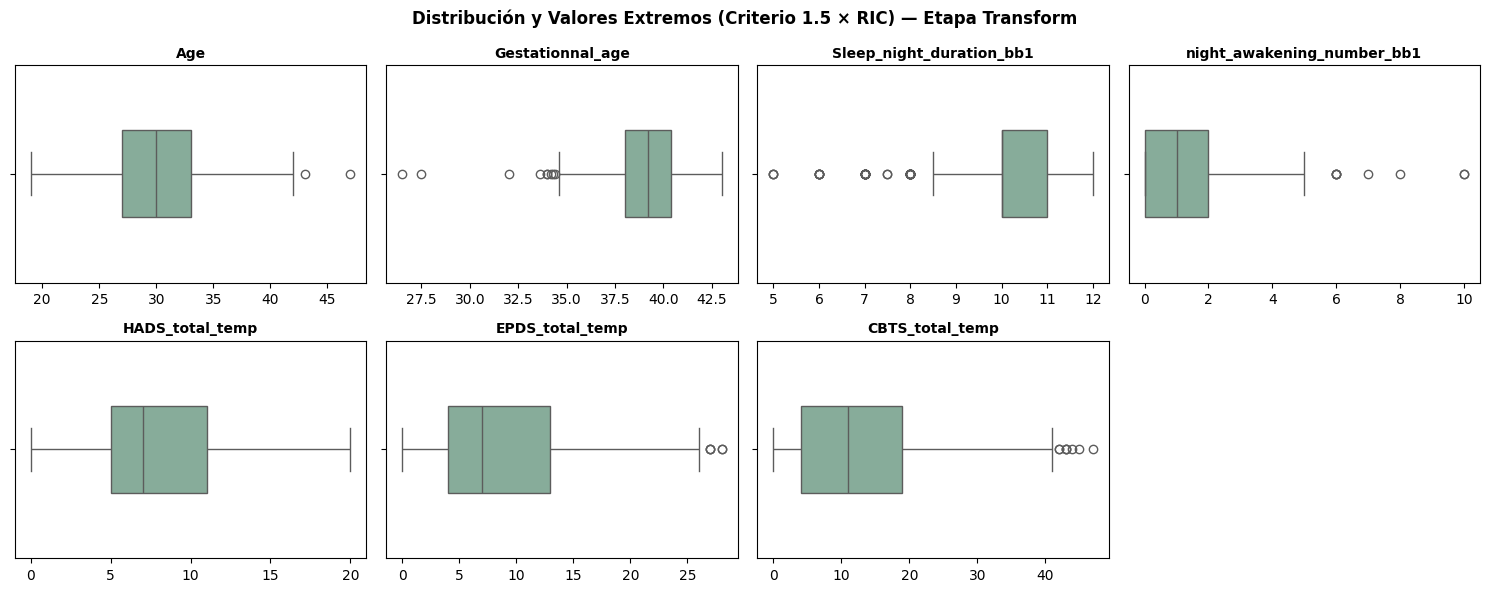

In [9]:
# 1. Copia temporal para auditar variables numéricas y puntajes totales (sin tocar df_corregido)
df_audit_outliers = df_corregido[
    ["Age", "Gestationnal_age", "Sleep_night_duration_bb1", "night_awakening_number_bb1"]
].copy()

# Agrupar las preguntas de cada cuestionario psicológico y sumar su puntaje total por madre
cols_hads = [c for c in df_corregido.columns if c.startswith("HADS_")]
cols_epds = [c for c in df_corregido.columns if c.startswith("EPDS_")]
cols_cbts = [c for c in df_corregido.columns if c.startswith("CBTS_")]

df_audit_outliers["HADS_total_temp"] = df_corregido[cols_hads].sum(axis=1, min_count=1)
df_audit_outliers["EPDS_total_temp"] = df_corregido[cols_epds].sum(axis=1, min_count=1)
df_audit_outliers["CBTS_total_temp"] = df_corregido[cols_cbts].sum(axis=1, min_count=1)

# 2. Calcular cuartiles, Rango Intercuartílico (RIC) y límites para detectar valores atípicos
resultados_outliers = []

for col in df_audit_outliers.columns:
    serie = df_audit_outliers[col].dropna()
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    ric = q3 - q1
    lim_inf = q1 - 1.5 * ric
    lim_sup = q3 + 1.5 * ric

    # Filtrar los valores que caen por debajo del límite inferior o por encima del superior
    outliers = serie[(serie < lim_inf) | (serie > lim_sup)]

    resultados_outliers.append({
        "Variable": col,
        "Min_Obs": round(serie.min(), 2),
        "Lim_Inf_RIC": round(lim_inf, 2),
        "Lim_Sup_RIC": round(lim_sup, 2),
        "Max_Obs": round(serie.max(), 2),
        "Outliers_Detectados": len(outliers),
        "%_Muestra": round((len(outliers) / len(serie)) * 100, 2)
    })

df_resumen_outliers = pd.DataFrame(resultados_outliers)
print("=== AUDITORÍA DE VALORES ATÍPICOS (CRITERIO 1.5 * RIC) ===\n")
print(df_resumen_outliers)

# 3. Dibujar los diagramas de caja (Boxplots) en una cuadrícula de 2 filas x 4 columnas
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
axes = axes.flatten()

posicion = 0
for col in df_audit_outliers.columns:
    sns.boxplot(x=df_audit_outliers[col], ax=axes[posicion], color="#81B29A", width=0.4)
    axes[posicion].set_title(col, fontsize=10, fontweight="bold")
    axes[posicion].set_xlabel("")
    posicion = posicion + 1

axes[7].axis("off")  # Oculta el último casillero vacío (son 7 variables en 8 espacios)
plt.suptitle("Distribución y Valores Extremos (Criterio 1.5 × RIC) — Etapa Transform", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

## 🗄️ 8. PROCESO ETL — LOAD: Base de Datos Transaccional OLTP (2NF)

Si bien el dataset curado poseía valores atómicos y un identificador único por madre (`Participant_number`), **no cumplía con la Primera Forma Normal (1NF)** debido a la presencia de **grupos repetidos horizontales**: los 47 ítems psicométricos estaban dispersos en columnas correlativas (`HADS_1`, `HADS_2`, `EPDS_1`, etc.).

Para alcanzar una arquitectura relacional normalizada hasta la **Segunda Forma Normal (2NF)**, se aplicó una reestructuración en dos etapas:
1. **Normalización a 1NF:** Se despivotaron (`melt`) las 47 columnas de ítems hacia una estructura vertical atomizada.
2. **Normalización a 2NF:** Se descompusieron los datos en **5 entidades** según su dependencia funcional, incorporando llaves primarias y foráneas para erradicar redundancias y dependencias parciales.

### 🏗️ Esquema Entidad-Relación (`perinatal_transaccional_2nf.db`)

* 👩 **`Madres`**: `Participant_number` *(PK)*, `Age`, `Marital_status_edit`, `Education`, `Gestationnal_age`, `Type_pregnancy`. Almacena exclusivamente los atributos sociodemográficos y obstétricos propios de la madre.
* 👶 **`Bebes`**: `Baby_ID` *(PK subrogada)*, `Participant_number` *(FK)*, `sex_baby1`, `Age_bb`, `Sleep_night_duration_bb1`, `night_awakening_number_bb1`, `how_falling_asleep_bb1`. Separa los atributos del lactante y soporta la cardinalidad real `1:N` (embarazos múltiples) sin duplicar registros maternos.
* 📖 **`Diccionario_Preguntas_Test`**: `pregunta_ID` *(PK)*, `Escala`, `Sujeto_evaluado`. Centraliza los metadatos de cada reactivo. Aislar la escala y el sujeto en esta tabla elimina las **dependencias parciales** en las tablas de respuestas (requisito estricto de la **2NF**) y facilita la escalabilidad del modelo.
* 📝 **`Test_madre`**: `Participant_number` *(PK, FK)*, `pregunta_ID` *(PK, FK)*, `Puntaje`. Tabla asociativa con clave primaria compuesta para las respuestas psicológicas maternas.
* 🧸 **`Test_bebe`**: `Baby_ID` *(PK, FK)*, `pregunta_ID` *(PK, FK)*, `Puntaje`. Tabla asociativa que vincula cada ítem de temperamento (`IBQ-R VSF`) directamente con `Baby_ID`.

🔒 **Integridad referencial:** Se activó `PRAGMA foreign_keys = ON;` en SQLite y se validó la carga mediante `PRAGMA foreign_key_check` y una consulta relacional `JOIN` de control.

> 💬 **Uso de IA:**  
> *"Dame un script en Python y SQLite para realizar la fase LOAD del proceso ETL, construyendo una base de datos transaccional (OLTP) a partir de mi DataFrame limpio (`df_corregido`), garantizando la normalización en Segunda Forma Normal (2NF).*  
> *1. Preparación (1NF a 2NF): Descomponer `df_corregido` en 5 entidades con sus respectivos atributos: `Madres` (6 atributos: `Participant_number` como PK, `Age`, `Marital_status_edit`, `Education`, `Gestationnal_age`, `Type_pregnancy`), `Bebes` (7 atributos: clave primaria subrogada `Baby_ID`, `Participant_number` como FK, `sex_baby1`, `Age_bb`, `Sleep_night_duration_bb1`, `night_awakening_number_bb1`, `how_falling_asleep_bb1`), `Diccionario_Preguntas_Test` (3 atributos: `pregunta_ID` como PK con los 47 ítems, `Escala` y `Sujeto_evaluado` para eliminar dependencias parciales), `Test_madre` (3 atributos despivotados con `melt`: `Participant_number` y `pregunta_ID` como PK compuesta/FK, y `Puntaje`) y `Test_bebe` (3 atributos vinculados a `Baby_ID` y despivotados con `melt`: `Baby_ID` y `pregunta_ID` como PK compuesta/FK, y `Puntaje`).* *Luego carga en SQLite.*  


> 🎯 **Síntesis del Modelo Relacional:**  
> Así, tengo mi **Base de Datos Transaccional (OLTP)** diseñada para capturar, guardar y modificar información operativa de forma **segura, rápida y sin datos duplicados** 🔒⚡.  
> **✅ Cumple con 2NF.**

In [10]:
# ==============================================================================
# FASE 1: DIVIDIR LA TABLA EN 5 TABLAS NORMALIZADAS (2NF)
# ==============================================================================

# 1. Tabla Madres (datos sociodemográficos y obstétricos)
cols_madres = [
    "Participant_number", "Age", "Marital_status_edit",
    "Education", "Gestationnal_age", "Type_pregnancy"
]
df_madres = df_corregido[cols_madres].copy()

# 2. Tabla Bebes (creamos un ID único Baby_ID del 1 al 410)
cols_bebes = [
    "Participant_number", "sex_baby1", "Age_bb",
    "Sleep_night_duration_bb1", "night_awakening_number_bb1", "how_falling_asleep_bb1"
]
df_bebes = df_corregido[cols_bebes].copy()
df_bebes.insert(0, "Baby_ID", range(1, len(df_bebes) + 1))

# 3. Tabla Diccionario_Preguntas_Test (catálogo de las 47 preguntas)
cols_test_madre = []
cols_test_bebe = []

for col in df_corregido.columns:
    if col.startswith(("CBTS_", "EPDS_", "HADS_")):
        cols_test_madre.append(col)
    elif col.startswith("IBQ_R_VSF_"):
        cols_test_bebe.append(col)

filas_diccionario = []
for pregunta in cols_test_madre:
    escala = pregunta.split("_")[0]  # Extrae "CBTS", "EPDS" o "HADS"
    filas_diccionario.append({"pregunta_ID": pregunta, "Escala": escala, "Sujeto_evaluado": "Madre"})

for pregunta in cols_test_bebe:
    filas_diccionario.append({"pregunta_ID": pregunta, "Escala": "IBQ-R VSF", "Sujeto_evaluado": "Bebe"})

df_diccionario = pd.DataFrame(filas_diccionario)

# 4. Tabla Test_madre (pasamos las columnas de preguntas a formato vertical con .melt-> 1NF)
df_test_madre = df_corregido.melt(
    id_vars=["Participant_number"],
    value_vars=cols_test_madre,
    var_name="pregunta_ID",
    value_name="Puntaje"
)

# 5. Tabla Test_bebe (vinculamos las preguntas del bebé con su Baby_ID)
df_temp_bebe = df_bebes[["Baby_ID", "Participant_number"]].merge(
    df_corregido[["Participant_number"] + cols_test_bebe],
    on="Participant_number"
)
df_test_bebe = df_temp_bebe.melt(
    id_vars=["Baby_ID"],
    value_vars=cols_test_bebe,
    var_name="pregunta_ID",
    value_name="Puntaje"
)

# ==============================================================================
# FASE 2: CREAR LA BASE DE DATOS EN SQLITE Y CARGAR LOS DATOS
# ==============================================================================

conn = sqlite3.connect("perinatal_transaccional_2nf.db")
cursor = conn.cursor()

# Activar el control estricto de claves foráneas en SQLite
cursor.execute("PRAGMA foreign_keys = ON;")

# Borrar tablas si ya existían y crear la estructura con claves primarias y foráneas
cursor.executescript("""
DROP TABLE IF EXISTS Test_bebe;
DROP TABLE IF EXISTS Test_madre;
DROP TABLE IF EXISTS Diccionario_Preguntas_Test;
DROP TABLE IF EXISTS Bebes;
DROP TABLE IF EXISTS Madres;

CREATE TABLE Madres (
    Participant_number INTEGER PRIMARY KEY,
    Age INTEGER,
    Marital_status_edit REAL,
    Education REAL,
    Gestationnal_age REAL,
    Type_pregnancy REAL
);

CREATE TABLE Bebes (
    Baby_ID INTEGER PRIMARY KEY,
    Participant_number INTEGER NOT NULL,
    sex_baby1 REAL,
    Age_bb REAL,
    Sleep_night_duration_bb1 REAL,
    night_awakening_number_bb1 REAL,
    how_falling_asleep_bb1 REAL,
    FOREIGN KEY (Participant_number) REFERENCES Madres(Participant_number)
);

CREATE TABLE Diccionario_Preguntas_Test (
    pregunta_ID TEXT PRIMARY KEY,
    Escala TEXT NOT NULL,
    Sujeto_evaluado TEXT NOT NULL
);

CREATE TABLE Test_madre (
    Participant_number INTEGER NOT NULL,
    pregunta_ID TEXT NOT NULL,
    Puntaje REAL,
    PRIMARY KEY (Participant_number, pregunta_ID),
    FOREIGN KEY (Participant_number) REFERENCES Madres(Participant_number),
    FOREIGN KEY (pregunta_ID) REFERENCES Diccionario_Preguntas_Test(pregunta_ID)
);

CREATE TABLE Test_bebe (
    Baby_ID INTEGER NOT NULL,
    pregunta_ID TEXT NOT NULL,
    Puntaje REAL,
    PRIMARY KEY (Baby_ID, pregunta_ID),
    FOREIGN KEY (Baby_ID) REFERENCES Bebes(Baby_ID),
    FOREIGN KEY (pregunta_ID) REFERENCES Diccionario_Preguntas_Test(pregunta_ID)
);
""")

# Insertar los datos respetando la jerarquía (primero tablas padre, luego hijas)
df_madres.to_sql("Madres", conn, if_exists="append", index=False)
df_diccionario.to_sql("Diccionario_Preguntas_Test", conn, if_exists="append", index=False)
df_bebes.to_sql("Bebes", conn, if_exists="append", index=False)
df_test_madre.to_sql("Test_madre", conn, if_exists="append", index=False)
df_test_bebe.to_sql("Test_bebe", conn, if_exists="append", index=False)

conn.commit()

# ==============================================================================
# FASE 3: VERIFICACIÓN FINAL DE LA BASE DE DATOS
# ==============================================================================
print("=== AUDITORÍA POST-LOAD EN SQLITE (2NF) ===\n")

tablas = ["Madres", "Bebes", "Diccionario_Preguntas_Test", "Test_madre", "Test_bebe"]
for t in tablas:
    cantidad = cursor.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0]
    print(f"- Tabla '{t}': {cantidad} registros")

errores_fk = cursor.execute("PRAGMA foreign_key_check;").fetchall()
print(f"\n- Errores de claves foráneas: {len(errores_fk)}")

query_prueba = """
SELECT
    m.Participant_number,
    m.Age AS Edad_Madre,
    d.Escala,
    SUM(tm.Puntaje) AS Puntaje_Total_Escala
FROM Madres m
JOIN Test_madre tm ON m.Participant_number = tm.Participant_number
JOIN Diccionario_Preguntas_Test d ON tm.pregunta_ID = d.pregunta_ID
WHERE m.Participant_number = 1
GROUP BY m.Participant_number, d.Escala;
"""
print("\n- Prueba de consulta relacional (Participante #1):")
print(pd.read_sql_query(query_prueba, conn))

conn.close()

=== AUDITORÍA POST-LOAD EN SQLITE (2NF) ===

- Tabla 'Madres': 410 registros
- Tabla 'Bebes': 410 registros
- Tabla 'Diccionario_Preguntas_Test': 47 registros
- Tabla 'Test_madre': 15170 registros
- Tabla 'Test_bebe': 4100 registros

- Errores de claves foráneas: 0

- Prueba de consulta relacional (Participante #1):
   Participant_number  Edad_Madre Escala  Puntaje_Total_Escala
0                   1          34   CBTS                   6.0
1                   1          34   EPDS                  13.0
2                   1          34   HADS                   9.0


## ⭐ 9. ALMACÉN DE DATOS OLAP: Modelado Dimensional (Esquema Estrella)

A partir de la base transaccional normalizada (`perinatal_transaccional_2nf.db`), se diseñó y pobló un **Almacén de Datos analítico (`perinatal_dw_estrella.db`)** bajo los principios del **Modelado Dimensional (Esquema Estrella)**, optimizado para consultas de agregación rápidas.

### 📐 Arquitectura Dimensional

* 🎯 **Tabla de Hechos — `fact_evaluacion_perinatal`:**  
  Consolida los hechos cuantitativos de cada evaluación (`evaluacion_id` *PK*), vinculados mediante claves foráneas (`Participant_number` y `Baby_ID`):
  * Puntajes totales agregados de escalas maternas (`CBTS_total`, `EPDS_total`, `HADS_total`) calculados desde `Test_madre`.
  * Puntaje promedio de temperamento infantil (`IBQ_promedio`) calculado desde `Test_bebe`.
  * Duración del sueño nocturno del lactante (`Sleep_night_duration_bb1`).
* 👩 **Dimensión Madre — `dim_madre`:**  
  Atributos descriptivos maternos y obstétricos, enriquecida durante la etapa de transformación OLAP con la variable categórica derivada **`condicion_nacimiento`** (`Pretermino (<38 sem)` vs. `A termino (>=38 sem)`).
* 👶 **Dimensión Bebé — `dim_bebe`:**  
  Atributos descriptivos del lactante (`sex_baby1`, `Age_bb`, `night_awakening_number_bb1`, `how_falling_asleep_bb1`).

### ❓ Preguntas Analíticas Respondidas mediante Consultas SQL (OLAP)

1. ¿Existe mayor ansiedad materna según el tipo de embarazo (`Type_pregnancy`)?
2. ¿Existe mayor ansiedad materna según la edad gestacional al nacer (`condicion_nacimiento`)?
3. ¿Existe mayor depresión materna según la edad gestacional al nacer?
4. ¿Varía la ansiedad materna según la rutina utilizada para dormir al bebé (`how_falling_asleep_bb1`)?
5. ¿Cuál es el promedio de depresión posparto (`EPDS_total`) y ansiedad (`HADS_total`) según el nivel educativo materno (`Education`)?
6. ¿Cuál es el promedio de depresión posparto (`EPDS_total`) según la forma en que concilia el sueño el bebé?
7. ¿Duermen menos horas nocturnas los bebés de madres con ansiedad clínicamente significativa (`HADS >= 8`)?
8. ¿Duermen menos horas nocturnas los bebés de madres con riesgo de depresión posparto (`EPDS >= 10`)?
9. ¿Presentan menores horas de sueño nocturno los bebés nacidos pretérmino (`< 38 semanas`)?

In [11]:
# ==============================================================================
# FASE 1: EXTRAER DE LA BASE 2NF Y ARMAR LAS 3 TABLAS DEL ESQUEMA ESTRELLA
# ==============================================================================
conn_oltp = sqlite3.connect("perinatal_transaccional_2nf.db")

# 1. Dimensión Madre (agregamos la categoría Pretérmino vs A término)
df_dim_madre = pd.read_sql_query("""
    SELECT
        Participant_number,
        Age,
        Marital_status_edit,
        Education,
        Gestationnal_age,
        CASE
            WHEN Gestationnal_age IS NULL THEN 'Sin dato'
            WHEN Gestationnal_age < 38 THEN 'Pretermino (<38 sem)'
            ELSE 'A termino (>=38 sem)'
        END AS condicion_nacimiento,
        Type_pregnancy
    FROM Madres;
""", conn_oltp)

# 2. Dimensión Bebé (características descriptivas del bebé)
df_dim_bebe = pd.read_sql_query("""
    SELECT
        Baby_ID,
        sex_baby1,
        Age_bb,
        night_awakening_number_bb1,
        how_falling_asleep_bb1
    FROM Bebes;
""", conn_oltp)

# 3. Tabla de Hechos (puntajes totales por escala + horas de sueño del bebé)
df_fact = pd.read_sql_query("""
    WITH puntajes_madre AS (
        SELECT
            tm.Participant_number,
            SUM(CASE WHEN d.Escala = 'CBTS' THEN tm.Puntaje END) AS CBTS_total,
            SUM(CASE WHEN d.Escala = 'EPDS' THEN tm.Puntaje END) AS EPDS_total,
            SUM(CASE WHEN d.Escala = 'HADS' THEN tm.Puntaje END) AS HADS_total
        FROM Test_madre tm
        JOIN Diccionario_Preguntas_Test d ON tm.pregunta_ID = d.pregunta_ID
        GROUP BY tm.Participant_number
    ),
    puntajes_bebe AS (
        SELECT
            Baby_ID,
            ROUND(AVG(Puntaje), 2) AS IBQ_promedio
        FROM Test_bebe
        GROUP BY Baby_ID
    )
    SELECT
        b.Participant_number,
        b.Baby_ID,
        pm.CBTS_total,
        pm.EPDS_total,
        pm.HADS_total,
        pb.IBQ_promedio,
        b.Sleep_night_duration_bb1
    FROM Bebes b
    LEFT JOIN puntajes_madre pm ON b.Participant_number = pm.Participant_number
    LEFT JOIN puntajes_bebe pb ON b.Baby_ID = pb.Baby_ID
    ORDER BY b.Baby_ID;
""", conn_oltp)

df_fact.insert(0, "evaluacion_id", range(1, len(df_fact) + 1))
conn_oltp.close()

# ==============================================================================
# FASE 2: CREAR EL DATA WAREHOUSE EN SQLITE (ESQUEMA ESTRELLA)
# ==============================================================================
conn_dw = sqlite3.connect("perinatal_dw_estrella.db")
cursor_dw = conn_dw.cursor()
cursor_dw.execute("PRAGMA foreign_keys = ON;")

cursor_dw.executescript("""
DROP TABLE IF EXISTS fact_evaluacion_perinatal;
DROP TABLE IF EXISTS dim_madre;
DROP TABLE IF EXISTS dim_bebe;

CREATE TABLE dim_madre (
    Participant_number INTEGER PRIMARY KEY,
    Age INTEGER,
    Marital_status_edit REAL,
    Education REAL,
    Gestationnal_age REAL,
    condicion_nacimiento TEXT,
    Type_pregnancy REAL
);

CREATE TABLE dim_bebe (
    Baby_ID INTEGER PRIMARY KEY,
    sex_baby1 REAL,
    Age_bb REAL,
    night_awakening_number_bb1 REAL,
    how_falling_asleep_bb1 REAL
);

CREATE TABLE fact_evaluacion_perinatal (
    evaluacion_id INTEGER PRIMARY KEY,
    Participant_number INTEGER NOT NULL,
    Baby_ID INTEGER NOT NULL,
    CBTS_total REAL,
    EPDS_total REAL,
    HADS_total REAL,
    IBQ_promedio REAL,
    Sleep_night_duration_bb1 REAL,
    FOREIGN KEY (Participant_number) REFERENCES dim_madre(Participant_number),
    FOREIGN KEY (Baby_ID) REFERENCES dim_bebe(Baby_ID)
);
""")

df_dim_madre.to_sql("dim_madre", conn_dw, if_exists="append", index=False)
df_dim_bebe.to_sql("dim_bebe", conn_dw, if_exists="append", index=False)
df_fact.to_sql("fact_evaluacion_perinatal", conn_dw, if_exists="append", index=False)
conn_dw.commit()

# ==============================================================================
# FASE 3: CONSULTAS ANALÍTICAS PARA RESPONDER LAS 9 PREGUNTAS
# ==============================================================================
print("=== RESULTADOS ANALÍTICOS DEL ALMACÉN DE DATOS ===\n")

# Pregunta 1: Ansiedad materna según tipo de embarazo
q1 = """
SELECT
    m.Type_pregnancy AS tipo_embarazo,
    COUNT(*) AS n_casos,
    ROUND(AVG(f.HADS_total), 2) AS promedio_ansiedad_HADS
FROM fact_evaluacion_perinatal f
JOIN dim_madre m ON f.Participant_number = m.Participant_number
GROUP BY m.Type_pregnancy
ORDER BY m.Type_pregnancy;
"""
print("1. Ansiedad materna según tipo de embarazo:")
print(pd.read_sql_query(q1, conn_dw))

# Preguntas 2 y 3: Ansiedad y depresión materna según nacimiento pretérmino vs a término
q2_3 = """
SELECT
    m.condicion_nacimiento,
    COUNT(*) AS n_casos,
    ROUND(AVG(f.HADS_total), 2) AS promedio_ansiedad_HADS,
    ROUND(AVG(f.EPDS_total), 2) AS promedio_depresion_EPDS
FROM fact_evaluacion_perinatal f
JOIN dim_madre m ON f.Participant_number = m.Participant_number
GROUP BY m.condicion_nacimiento;
"""
print("\n2 y 3. Ansiedad y depresión materna según nacimiento pretérmino vs. a término:")
print(pd.read_sql_query(q2_3, conn_dw))

# Preguntas 4 y 6: Ansiedad y depresión materna según cómo se duerme el bebé
q4_6 = """
SELECT
    b.how_falling_asleep_bb1 AS forma_dormirse_bebe,
    COUNT(*) AS n_casos,
    ROUND(AVG(f.HADS_total), 2) AS promedio_ansiedad_HADS,
    ROUND(AVG(f.EPDS_total), 2) AS promedio_depresion_EPDS
FROM fact_evaluacion_perinatal f
JOIN dim_bebe b ON f.Baby_ID = b.Baby_ID
GROUP BY b.how_falling_asleep_bb1
ORDER BY b.how_falling_asleep_bb1;
"""
print("\n4 y 6. Ansiedad y depresión materna según cómo se duerme el bebé:")
print(pd.read_sql_query(q4_6, conn_dw))

# Pregunta 5: Promedio de depresión y ansiedad según nivel educativo
q5 = """
SELECT
    m.Education AS nivel_educativo,
    COUNT(*) AS n_casos,
    ROUND(AVG(f.EPDS_total), 2) AS promedio_depresion_EPDS,
    ROUND(AVG(f.HADS_total), 2) AS promedio_ansiedad_HADS
FROM fact_evaluacion_perinatal f
JOIN dim_madre m ON f.Participant_number = m.Participant_number
GROUP BY m.Education
ORDER BY m.Education;
"""
print("\n5. Depresión y ansiedad materna según nivel educativo:")
print(pd.read_sql_query(q5, conn_dw))

# Pregunta 7: Horas de sueño del bebé según ansiedad materna (corte clínico HADS >= 8)
q7 = """
SELECT
    CASE
        WHEN HADS_total >= 8 THEN 'Mayor ansiedad (HADS >= 8)'
        ELSE 'Menor ansiedad (HADS < 8)'
    END AS grupo_ansiedad_materna,
    COUNT(*) AS n_casos,
    ROUND(AVG(Sleep_night_duration_bb1), 2) AS promedio_horas_sueno_bebe
FROM fact_evaluacion_perinatal
WHERE Sleep_night_duration_bb1 IS NOT NULL
  AND HADS_total IS NOT NULL
GROUP BY grupo_ansiedad_materna;
"""
print("\n7. Horas de sueño nocturno del bebé según ansiedad materna:")
print(pd.read_sql_query(q7, conn_dw))

# Pregunta 8: Horas de sueño del bebé según depresión materna (corte clínico EPDS >= 10)
q8 = """
SELECT
    CASE
        WHEN EPDS_total >= 10 THEN 'Mayor depresion (EPDS >= 10)'
        ELSE 'Menor depresion (EPDS < 10)'
    END AS grupo_depresion_materna,
    COUNT(*) AS n_casos,
    ROUND(AVG(Sleep_night_duration_bb1), 2) AS promedio_horas_sueno_bebe
FROM fact_evaluacion_perinatal
WHERE Sleep_night_duration_bb1 IS NOT NULL
  AND EPDS_total IS NOT NULL
GROUP BY grupo_depresion_materna;
"""
print("\n8. Horas de sueño nocturno del bebé según depresión materna:")
print(pd.read_sql_query(q8, conn_dw))

# Pregunta 9: Horas de sueño en bebés nacidos pretérmino (<38 semanas) vs a término
q9 = """
SELECT
    m.condicion_nacimiento,
    COUNT(*) AS n_casos,
    ROUND(AVG(f.Sleep_night_duration_bb1), 2) AS promedio_horas_sueno_bebe
FROM fact_evaluacion_perinatal f
JOIN dim_madre m ON f.Participant_number = m.Participant_number
WHERE f.Sleep_night_duration_bb1 IS NOT NULL
GROUP BY m.condicion_nacimiento;
"""
print("\n9. Horas de sueño nocturno en bebés nacidos pretérmino (<38 sem) vs. a término:")
print(pd.read_sql_query(q9, conn_dw))

conn_dw.close()

=== RESULTADOS ANALÍTICOS DEL ALMACÉN DE DATOS ===

1. Ansiedad materna según tipo de embarazo:
   tipo_embarazo  n_casos  promedio_ansiedad_HADS
0            1.0      405                    7.87
1            2.0        5                    5.40

2 y 3. Ansiedad y depresión materna según nacimiento pretérmino vs. a término:
   condicion_nacimiento  n_casos  promedio_ansiedad_HADS  \
0  A termino (>=38 sem)      339                    7.63   
1  Pretermino (<38 sem)       71                    8.85   

   promedio_depresion_EPDS  
0                     8.85  
1                    10.01  

4 y 6. Ansiedad y depresión materna según cómo se duerme el bebé:
   forma_dormirse_bebe  n_casos  promedio_ansiedad_HADS  \
0                  1.0       90                    7.42   
1                  2.0       74                    8.16   
2                  3.0       22                    7.86   
3                  4.0      177                    7.63   
4                  5.0       47             

## 🚀 10. VISUALIZACIÓN INTERACTIVA: Tablero Analítico en Streamlit + Plotly

Conectada directamente al almacén dimensional (`perinatal_dw_estrella.db`) mediante consultas SQL (`JOIN` y `GROUP BY` entre la tabla de hechos y ambas dimensiones), se desarrolló una **aplicación web interactiva en Streamlit + Plotly (`app.py`)**, desplegada desde Google Colab a través de un túnel público con `cloudflared`.

> 💬 **Uso de IA:**  
> *"Arma el código en Python para crear un tablero analítico interactivo en Streamlit y Plotly (`app.py`) desde Google Colab conectado a mi almacén de datos SQLite `perinatal_dw_estrella.db` que visualice los resultados de mis 9 preguntas."*

> 💡 **Síntesis clínica de los hallazgos visualizados:**  
> Los gráficos evidencian que el **nacimiento pretérmino (`< 38 semanas`)**, el **menor nivel educativo materno** y determinadas **rutinas para conciliar el sueño infantil** se asocian con puntajes promedio que superan los umbrales de riesgo clínico de ansiedad (`HADS >= 8`) y depresión posparto (`EPDS >= 10`). Asimismo, mientras que la prematurez no reduce las horas totales de sueño nocturno del lactante (`10.11` vs. `10.20` hs), la **depresión materna (`EPDS >= 10`)** se vincula con una disminución perceptible del descanso nocturno infantil (`9.93` vs. `10.37` hs).



In [12]:
!pip install -q streamlit

In [13]:
%%writefile app.py
import sqlite3
import pandas as pd
import streamlit as st
import plotly.express as px

# Configuración general de la página
st.set_page_config(
    page_title="Dashboard Salud Mental Perinatal",
    page_icon="👶",
    layout="wide"
)

st.title("Tablero Analítico: Salud Mental Materna y Sueño Infantil")
st.markdown("Resultados del almacén de datos (**Esquema Estrella**) sobre **410 díadas madre-bebé**.")

# Conexión al Data Warehouse en SQLite
conn = sqlite3.connect("perinatal_dw_estrella.db")

# Indicadores principales (KPIs)
df_kpis = pd.read_sql_query("""
    SELECT
        COUNT(*) AS total_casos,
        ROUND(AVG(HADS_total), 2) AS prom_ansiedad,
        ROUND(AVG(EPDS_total), 2) AS prom_depresion,
        ROUND(AVG(Sleep_night_duration_bb1), 2) AS prom_sueno
    FROM fact_evaluacion_perinatal;
""", conn)

col1, col2, col3, col4 = st.columns(4)
col1.metric("Díadas Evaluadas", int(df_kpis["total_casos"][0]))
col2.metric("Ansiedad Media (HADS)", f"{df_kpis['prom_ansiedad'][0]} pts", "Corte clínico: ≥ 8")
col3.metric("Depresión Media (EPDS)", f"{df_kpis['prom_depresion'][0]} pts", "Corte clínico: ≥ 10")
col4.metric("Sueño Nocturno Bebé", f"{df_kpis['prom_sueno'][0]} hs", "409 registros válidos")

st.divider()

# ==============================================================================
# BLOQUE 1: FACTORES OBSTÉTRICOS Y EDUCATIVOS (PREGUNTAS 1, 2, 3 Y 5)
# ==============================================================================
st.header("1. Salud Mental Materna según Factores Obstétricos y Educativos")
c1, c2 = st.columns(2)

# Pregunta 1: Ansiedad según tipo de embarazo
with c1:
    df_q1 = pd.read_sql_query("""
        SELECT
            CAST(m.Type_pregnancy AS INT) AS Tipo_Embarazo,
            COUNT(*) AS Casos,
            ROUND(AVG(f.HADS_total), 2) AS Ansiedad_HADS
        FROM fact_evaluacion_perinatal f
        JOIN dim_madre m ON f.Participant_number = m.Participant_number
        GROUP BY m.Type_pregnancy
        ORDER BY m.Type_pregnancy;
    """, conn)
    df_q1["Tipo_Embarazo"] = df_q1["Tipo_Embarazo"].astype(str)

    fig1 = px.bar(
        df_q1, x="Tipo_Embarazo", y="Ansiedad_HADS", text_auto=True,
        hover_data=["Casos"], color="Tipo_Embarazo",
        title="P1. Ansiedad Materna (HADS) según Tipo de Embarazo",
        labels={"Tipo_Embarazo": "Tipo de embarazo (1=Único, 2=Múltiple)", "Ansiedad_HADS": "Puntaje HADS"}
    )
    fig1.add_hline(y=8, line_dash="dash", line_color="red", annotation_text="Corte clínico (8)")
    fig1.update_layout(showlegend=False)
    st.plotly_chart(fig1, use_container_width=True)

# Preguntas 2 y 3: Ansiedad y Depresión según nacimiento pretérmino vs a término
with c2:
    df_q2_3 = pd.read_sql_query("""
        SELECT
            m.condicion_nacimiento AS Condicion,
            ROUND(AVG(f.HADS_total), 2) AS Ansiedad_HADS,
            ROUND(AVG(f.EPDS_total), 2) AS Depresion_EPDS
        FROM fact_evaluacion_perinatal f
        JOIN dim_madre m ON f.Participant_number = m.Participant_number
        GROUP BY m.condicion_nacimiento;
    """, conn)

    df_q2_3_largo = df_q2_3.melt(id_vars="Condicion", var_name="Escala", value_name="Promedio")

    fig2_3 = px.bar(
        df_q2_3_largo, x="Condicion", y="Promedio", color="Escala",
        barmode="group", text_auto=True,
        title="P2 y P3. Ansiedad y Depresión: Pretérmino vs. A Término",
        labels={"Condicion": "Condición de nacimiento", "Promedio": "Puntaje promedio"}
    )
    fig2_3.add_hline(y=8, line_dash="dot", line_color="blue", annotation_text="Corte HADS (8)")
    fig2_3.add_hline(y=10, line_dash="dash", line_color="red", annotation_text="Corte EPDS (10)")
    st.plotly_chart(fig2_3, use_container_width=True)

# Pregunta 5: Depresión y Ansiedad según Nivel Educativo
df_q5 = pd.read_sql_query("""
    SELECT
        CAST(m.Education AS INT) AS Nivel_Educativo,
        ROUND(AVG(f.EPDS_total), 2) AS Depresion_EPDS,
        ROUND(AVG(f.HADS_total), 2) AS Ansiedad_HADS
    FROM fact_evaluacion_perinatal f
    JOIN dim_madre m ON f.Participant_number = m.Participant_number
    GROUP BY m.Education
    ORDER BY m.Education;
""", conn)
df_q5["Nivel_Educativo"] = df_q5["Nivel_Educativo"].astype(str)
df_q5_largo = df_q5.melt(id_vars="Nivel_Educativo", var_name="Escala", value_name="Promedio")

fig5 = px.bar(
    df_q5_largo, x="Nivel_Educativo", y="Promedio", color="Escala",
    barmode="group", text_auto=True,
    title="P5. Depresión (EPDS) y Ansiedad (HADS) según Nivel Educativo Materno",
    labels={"Nivel_Educativo": "Nivel educativo (1 a 5)", "Promedio": "Puntaje promedio"}
)
fig5.add_hline(y=10, line_dash="dash", line_color="red", annotation_text="Corte EPDS (10)")
st.plotly_chart(fig5, use_container_width=True)

st.divider()

# ==============================================================================
# BLOQUE 2: RUTINA PARA DORMIR AL BEBÉ Y SALUD MENTAL (PREGUNTAS 4 Y 6)
# ==============================================================================
st.header("2. Salud Mental Materna según Cómo se Duerme el Bebé")

df_q4_6 = pd.read_sql_query("""
    SELECT
        CAST(b.how_falling_asleep_bb1 AS INT) AS Forma_Dormirse,
        ROUND(AVG(f.HADS_total), 2) AS Ansiedad_HADS,
        ROUND(AVG(f.EPDS_total), 2) AS Depresion_EPDS
    FROM fact_evaluacion_perinatal f
    JOIN dim_bebe b ON f.Baby_ID = b.Baby_ID
    GROUP BY b.how_falling_asleep_bb1
    ORDER BY b.how_falling_asleep_bb1;
""", conn)
df_q4_6["Forma_Dormirse"] = df_q4_6["Forma_Dormirse"].astype(str)
df_q4_6_largo = df_q4_6.melt(id_vars="Forma_Dormirse", var_name="Escala", value_name="Promedio")

fig4_6 = px.bar(
    df_q4_6_largo, x="Forma_Dormirse", y="Promedio", color="Escala",
    barmode="group", text_auto=True,
    title="P4 y P6. Ansiedad y Depresión Materna según Forma de Conciliar el Sueño del Bebé",
    labels={"Forma_Dormirse": "Categoría de cómo se duerme el bebé (1 a 5)", "Promedio": "Puntaje promedio"}
)
fig4_6.add_hline(y=8, line_dash="dot", line_color="blue", annotation_text="Corte HADS (8)")
fig4_6.add_hline(y=10, line_dash="dash", line_color="red", annotation_text="Corte EPDS (10)")
st.plotly_chart(fig4_6, use_container_width=True)

st.divider()

# ==============================================================================
# BLOQUE 3: HORAS DE SUEÑO NOCTURNO DEL BEBÉ (PREGUNTAS 7, 8 Y 9)
# ==============================================================================
st.header("3. Duración del Sueño Nocturno del Bebé (en Horas Decimales)")
c3, c4, c5 = st.columns(3)

# Pregunta 7: Sueño del bebé según ansiedad materna
with c3:
    df_q7 = pd.read_sql_query("""
        SELECT
            CASE
                WHEN HADS_total >= 8 THEN 'Mayor ansiedad (≥8)'
                ELSE 'Menor ansiedad (<8)'
            END AS Grupo_Ansiedad,
            ROUND(AVG(Sleep_night_duration_bb1), 2) AS Horas_Sueno
        FROM fact_evaluacion_perinatal
        WHERE Sleep_night_duration_bb1 IS NOT NULL AND HADS_total IS NOT NULL
        GROUP BY Grupo_Ansiedad;
    """, conn)

    fig7 = px.bar(
        df_q7, x="Grupo_Ansiedad", y="Horas_Sueno", text_auto=True,
        color="Grupo_Ansiedad", title="P7. Sueño Bebé vs. Ansiedad Materna",
        labels={"Grupo_Ansiedad": "Ansiedad (HADS)", "Horas_Sueno": "Horas de sueño"}
    )
    fig7.update_yaxes(range=[8, 11])
    fig7.update_layout(showlegend=False)
    st.plotly_chart(fig7, use_container_width=True)

# Pregunta 8: Sueño del bebé según depresión materna
with c4:
    df_q8 = pd.read_sql_query("""
        SELECT
            CASE
                WHEN EPDS_total >= 10 THEN 'Mayor depresión (≥10)'
                ELSE 'Menor depresión (<10)'
            END AS Grupo_Depresion,
            ROUND(AVG(Sleep_night_duration_bb1), 2) AS Horas_Sueno
        FROM fact_evaluacion_perinatal
        WHERE Sleep_night_duration_bb1 IS NOT NULL AND EPDS_total IS NOT NULL
        GROUP BY Grupo_Depresion;
    """, conn)

    fig8 = px.bar(
        df_q8, x="Grupo_Depresion", y="Horas_Sueno", text_auto=True,
        color="Grupo_Depresion", title="P8. Sueño Bebé vs. Depresión Materna",
        labels={"Grupo_Depresion": "Depresión (EPDS)", "Horas_Sueno": "Horas de sueño"}
    )
    fig8.update_yaxes(range=[8, 11])
    fig8.update_layout(showlegend=False)
    st.plotly_chart(fig8, use_container_width=True)

# Pregunta 9: Sueño del bebé pretérmino vs a término
with c5:
    df_q9 = pd.read_sql_query("""
        SELECT
            m.condicion_nacimiento AS Condicion,
            ROUND(AVG(f.Sleep_night_duration_bb1), 2) AS Horas_Sueno
        FROM fact_evaluacion_perinatal f
        JOIN dim_madre m ON f.Participant_number = m.Participant_number
        WHERE f.Sleep_night_duration_bb1 IS NOT NULL
        GROUP BY m.condicion_nacimiento;
    """, conn)

    fig9 = px.bar(
        df_q9, x="Condicion", y="Horas_Sueno", text_auto=True,
        color="Condicion", title="P9. Sueño Bebé: Pretérmino vs. A Término",
        labels={"Condicion": "Nacimiento", "Horas_Sueno": "Horas de sueño"}
    )
    fig9.update_yaxes(range=[8, 11])
    fig9.update_layout(showlegend=False)
    st.plotly_chart(fig9, use_container_width=True)

conn.close()

Overwriting app.py


In [14]:
# 1. Descargar cliente de Cloudflare Tunnel
!wget -q -nc https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64
!chmod +x cloudflared-linux-amd64

# 2. Iniciar Streamlit en segundo plano en el puerto 8501
!nohup streamlit run app.py --server.port 8501 --server.headless true > /content/streamlit.log 2>&1 &
!sleep 3

# 3. Abrir túnel web (haz clic en el enlace https://...trycloudflare.com que aparece abajo)
!./cloudflared-linux-amd64 tunnel --url http://localhost:8501

2026-11-22T04:10:03Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-11-22T04:10:03Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-11-22T04:10:08Z INF +--------------------------------------------------------------------------------------------+
2026-11-22T04:10:08Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-11-22T04:10:08Z INF |  https://crowd-binding-holdings-reactions.trycloudflar

## ✅ 11. CIERRE DEL PROYECTO

### 🏗️ Síntesis de Ingeniería de Datos y Arquitectura

El proyecto recorre todo el flujo de ingeniería de datos, transformando un archivo plano .csv en una arquitectura lista para el análisis:

- **Extracción y Limpieza (ETL):** Se descargaron los datos automáticamente desde Kaggle (`kagglehub`) y se limpió la base ajustando tipos de datos (`int64` / `float64`), pasando horas (`'HH:MM'`) a decimales, eliminando columnas redundantes, reemplazando el error `'99:99'` por `NaN` y auditando valores extremos ($1.5 \times \text{RIC}$) sin eliminar casos clínicos reales.
- **Base de Datos Normalizada (OLTP — 2NF):** Para evitar datos repetidos, se reestructuró la tabla original y se organizó en **5 tablas relacionadas** en SQLite (`perinatal_transaccional_2nf.db`), incorporando claves subrogadas (`Baby_ID`).
- **Almacén de Datos Analítico (OLAP — Esquema Estrella):** Se creó un Data Warehouse en SQLite (`perinatal_dw_estrella.db`) compuesto por una **tabla de hechos** (`fact_evaluacion_perinatal`) con métricas agregadas y **dos dimensiones** (`dim_madre`, `dim_bebe`) para agilizar consultas.
- **Visualización Interactiva:** El almacén se conecta mediante SQL a un tablero web en **Streamlit y Plotly**, mostrando gráficos comparativos con umbrales clínicos que responden las 9 preguntas de investigación.
